# Исследовательский анализ данных (EDA) и проверка статистических гипотез
## Проект: Мониторинг и скоринг технологического брака, отзывов и стабильности ЛС на рынке РФ (PRRI)

**Автор:** Химик-аналитик / Инженер-технолог R&D (6+ лет в фармразработке ТЛФ, валидации и исследованиях стабильности) → Data Analyst  
**Источник данных:** Живой реестр Росздравнадзора «Поиск изъятых из обращения лекарственных средств» (`2020–2026 гг.`, `10 046` уникальных записей).

---

### Цели исследования:
1. **Профилирование и аудит качества данных (Data Quality):** отделить реальные инциденты технологического и химико-микробиологического брака от писем о снятии карантина («Разрешение реализации») и превентивных отзывов без указания фармакопейного показателя.
2. **Анализ SQL-витрин (CTE и оконные функции):** изучить помесячную динамику забраковок (`LAG`, `MA3`, `YTD`), концентрацию риска по закону Парето (`SUM() OVER`) и матрицу «Лекарственная форма × Категория брака».
3. **Валидация кастомной бизнес-метрики `PRRI` (Pharma Recall Risk Index) и `TDR` (Technological Defect Share):** показать, как учет критичности дефекта ($W_{\text{defect}}$), серийности ($W_{\text{chronic}}$) и давности ($e^{-\lambda \Delta t}$) отделяет случайные полиграфические ошибки упаковки от системных провалов технологии производства.
4. **Проверка 4 статистических гипотез (`scipy.stats`):**
   - **Гипотеза 1 ($\chi^2$ Пирсона + $V$ Крамера):** Различается ли профиль критичности брака (Level 1 / Level 2 / Level 3) у отечественных (РФ) и зарубежных производителей?
   - **Гипотеза 2 ($\chi^2$ Пирсона + $V$ Крамера):** Зависит ли доля технологического брака (`TDR %`) от группы лекарственной формы (ТЛФ vs Стерильные/Инъекции vs ЖЛФ vs МЛФ)?
   - **Гипотеза 3 ($U$-критерий Манна-Уитни):** Различается ли интегральный индекс риска `PRRI` российских и зарубежных производственных площадок?
   - **Гипотеза 4 ($H$-критерий Краскела-Уоллиса):** Существует ли статистически значимая календарная сезонность по кварталам года в публикации писем о забраковке ЛС?

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.database import get_db_engine, query_df
from src.stats_tests import run_all_hypothesis_tests

plt.rcParams['figure.figsize'] = (11, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 140)

engine = get_db_engine(f"sqlite:///{(PROJECT_ROOT / 'data/processed/pharma_quality.db').as_posix()}")
print('Подключение к БД активно:', engine.url)

2026-11-04 18:28:14 | INFO     | rzn_database | Успешное подключение к СУБД: SQLITE


Подключение к БД активно: sqlite:///C:/Users/User/Desktop/OpenCode/PRRI/data/processed/pharma_quality.db


---
## 1. Аудит данных и структура реестра Росздравнадзора (2020–2026)

При первичном профилировании выгрузки из API Росздравнадзора (`10 046` дедуплицированных записей) выявлены важные особенности генерации данных:
1. **`Разрешение реализации` (`208` строк):** это письма о возврате ранее приостановленных серий в оборот после успешной перепроверки. Включение их в расчет брака было бы грубой аналитической ошибкой, поэтому в пайплайне `src/cleaner.py` для них установлен флаг `is_recall_event = 0` и вес $W_{\text{action}} = 0.0$.
2. **Превентивные отзывы производителей (`Level 0`, `5 636` строк):** отзывы со статусом `оригинальное ЛС` без заполненного поля показателя в веб-реестре (причина внутри PDF-письма, например глобальный отзыв сартанов «Лозап» в 2021 г.).
3. **Верифицированные лабораторные дефекты (`Level 1–3`, `4 202` серии):** записи с конкретным фармакопейным показателем брака (`Растворение`, `Родственные примеси`, `Описание`, `Количественное определение`, `Микробиологическая чистота`, `Маркировка` и др.) или доказанным фальсификатом. Именно на них строится технологический скоринг `PRRI` и расчет `TDR (%)`.

In [2]:
df_overview = query_df('''
SELECT
    is_recall_event,
    defect_level_num,
    defect_level,
    COUNT(*) AS records_count,
    COUNT(DISTINCT letter_number) AS unique_letters,
    COUNT(DISTINCT manufacturer_clean) AS unique_manufacturers,
    ROUND(SUM(prri_incident_score), 2) AS total_verified_prri
FROM fact_recalls
GROUP BY is_recall_event, defect_level_num, defect_level
ORDER BY is_recall_event DESC, defect_level_num DESC
''', engine=engine)

display(df_overview)

,is_recall_event,defect_level_num,defect_level,records_count,unique_letters,unique_manufacturers,total_verified_prri
0,1,3,Level 3: Критический брак АФС и микробиологии ...,1965,770,175,8223.35
1,1,2,Level 2: Технологический брак формы (2.5),1358,697,131,2740.87
2,1,1,Level 1: Логистика и упаковка (1.0),879,357,149,576.59
3,1,0,Level 0: Превентивный отзыв (без показателя в ...,5636,175,102,0.00
4,0,3,Level 3: Критический брак АФС и микробиологии ...,1,1,1,0.00
5,0,2,Level 2: Технологический брак формы (2.5),3,3,3,0.00
6,0,1,Level 1: Логистика и упаковка (1.0),2,1,1,0.00
7,0,0,Level 0: Превентивный отзыв (без показателя в ...,202,56,25,0.00


---
## 2. Структура верифицированных показателей брака (доменная классификация R&D)

Все 161 уникальных текстовых формулировок из поля `col11` сгруппированы в **11 фармакопейно-технологических категорий** по 3 уровням критичности:
- **Level 3 (вес `5.0`) — Критический брак АФС и микробиологии:** прямая угроза безопасности пациента или потери терапевтического эффекта (`Родственные и посторонние примеси`, `Количественное определение`, `Микробиология, стерильность и эндотоксины`, `Подлинность`, `Фальсификат`).
- **Level 2 (вес `2.5`) — Технологический брак лекарственной формы:** сбой грануляции, таблетирования, нанесения оболочки или фильтрации раствора (`Растворение и распадаемость`, `Описание, цветность и прозрачность`, `Механические включения`, `Однородность дозирования и массы`, `pH, влага, осмоляльность`).
- **Level 1 (вес `1.0`) — Логистика и упаковка:** полиграфические и упаковочные несоответствия (`Маркировка и упаковка`).

,defect_level,defect_category,batches_count,share_pct,total_prri_score
0,Level 3: Критический брак АФС и микробиологии ...,Родственные и посторонние примеси (стабильност...,1187,28.25,4372.64
1,Level 1: Логистика и упаковка (1.0),Маркировка и упаковка,879,20.92,576.59
2,Level 2: Технологический брак формы (2.5),Растворение и распадаемость,547,13.02,1382.28
3,Level 2: Технологический брак формы (2.5),"Описание, цветность и прозрачность",519,12.35,806.12
4,Level 3: Критический брак АФС и микробиологии ...,Количественное определение и содержание АФС,462,10.99,2784.53
5,Level 2: Технологический брак формы (2.5),Механические включения,153,3.64,342.96
6,Level 3: Критический брак АФС и микробиологии ...,"Микробиология, стерильность и эндотоксины",142,3.38,522.89
7,Level 3: Критический брак АФС и микробиологии ...,Подлинность и идентификация,108,2.57,366.55
8,Level 2: Технологический брак формы (2.5),"Физико-химические параметры (pH, влага, осмоля...",74,1.76,97.30
9,Level 3: Критический брак АФС и микробиологии ...,Фальсификат / Незаконный оборот,66,1.57,176.74


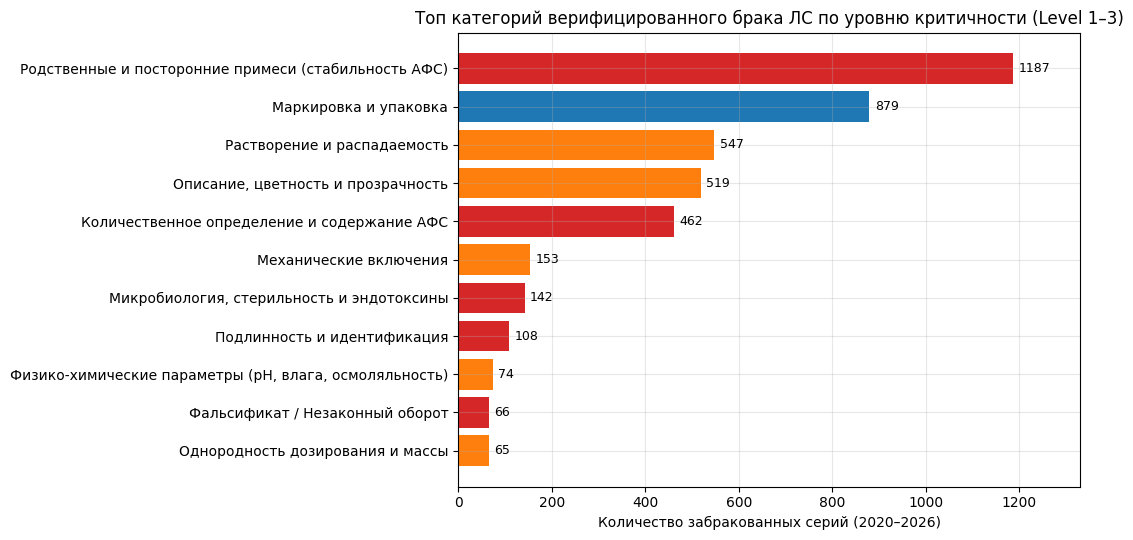

In [3]:
df_cats = query_df('''
SELECT
    defect_level,
    defect_category,
    COUNT(*) AS batches_count,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS share_pct,
    ROUND(SUM(prri_incident_score), 2) AS total_prri_score
FROM fact_recalls
WHERE is_recall_event = 1 AND has_explicit_defect = 1
GROUP BY defect_level, defect_category
ORDER BY batches_count DESC
''', engine=engine)

display(df_cats)

fig, ax = plt.subplots(figsize=(11, 5.5))
colors = [
    '#d62728' if 'Level 3' in lvl else ('#ff7f0e' if 'Level 2' in lvl else '#1f77b4')
    for lvl in df_cats['defect_level']
]
bars = ax.barh(df_cats['defect_category'][::-1], df_cats['batches_count'][::-1], color=colors[::-1])
ax.set_xlabel('Количество забракованных серий (2020–2026)')
ax.set_title('Топ категорий верифицированного брака ЛС по уровню критичности (Level 1–3)')
for bar in bars:
    w = bar.get_width()
    ax.text(w + 12, bar.get_y() + bar.get_height()/2, f'{int(w)}', va='center', fontsize=9)
ax.set_xlim(0, df_cats['batches_count'].max() * 1.12)
plt.tight_layout()
plt.show()

---
## 3. Анализ SQL-витрин: помесячная динамика, закон Парето и матрица R&D

### 3.1. Помесячная динамика и 3-месячное скользящее среднее (`v_monthly_defect_dynamics`)
С помощью оконных функций `LAG()` и `AVG() OVER (ROWS BETWEEN 2 PRECEDING AND CURRENT ROW)` проследим тренд выявляемости технологического брака:

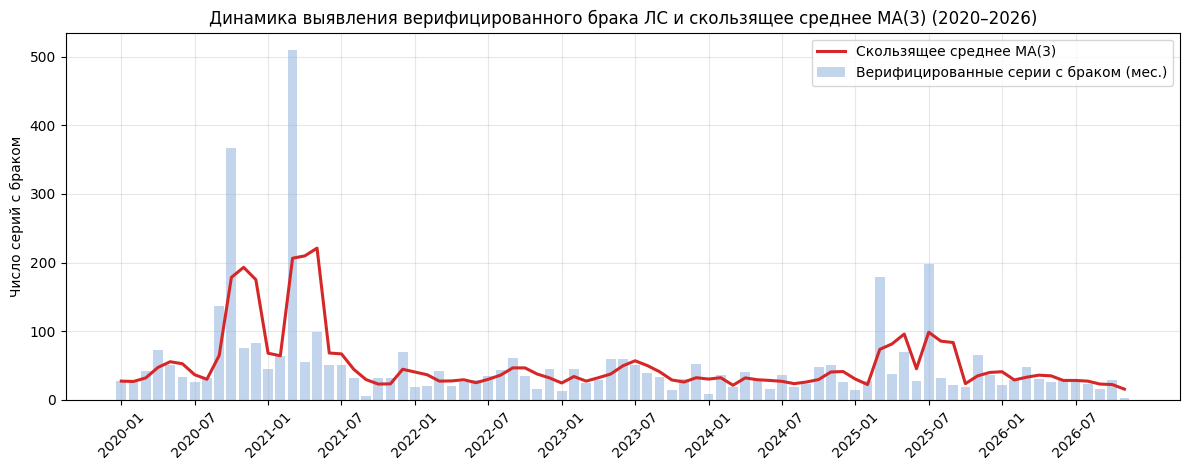

,year_month,verified_defects,prev_month_verified,mom_verified_diff,mom_verified_growth_pct,ma3_verified_defects,ytd_verified_defects,monthly_tdr_pct,monthly_prri_score
71,2025-12,36,65.0,-29.0,-44.6,39.7,724,75.0,270.32
72,2026-01,21,36.0,-15.0,-41.7,40.7,21,71.4,189.94
73,2026-02,29,21.0,8.0,38.1,28.7,50,93.1,296.96
74,2026-03,48,29.0,19.0,65.5,32.7,98,89.6,481.40
75,2026-04,30,48.0,-18.0,-37.5,35.7,128,73.3,237.14
76,2026-05,26,30.0,-4.0,-13.3,34.7,154,69.2,173.99
77,2026-06,28,26.0,2.0,7.7,28.0,182,64.3,187.99
78,2026-07,30,28.0,2.0,7.1,28.0,212,86.7,223.98
79,2026-08,23,30.0,-7.0,-23.3,27.0,235,95.7,197.24
80,2026-09,15,23.0,-8.0,-34.8,22.7,250,86.7,95.30


In [4]:
df_dyn = query_df("SELECT * FROM v_monthly_defect_dynamics ORDER BY year_month", engine=engine)

fig, ax1 = plt.subplots(figsize=(12, 4.8))
x_idx = np.arange(len(df_dyn))
ax1.bar(x_idx, df_dyn['verified_defects'], color='#aec7e8', alpha=0.75, label='Верифицированные серии с браком (мес.)')
ax1.plot(x_idx, df_dyn['ma3_verified_defects'], color='#d62728', linewidth=2.2, label='Скользящее среднее MA(3)')

step = 6
ax1.set_xticks(x_idx[::step])
ax1.set_xticklabels(df_dyn['year_month'].iloc[::step], rotation=45)
ax1.set_ylabel('Число серий с браком')
ax1.set_title('Динамика выявления верифицированного брака ЛС и скользящее среднее MA(3) (2020–2026)')
ax1.legend(loc='upper right')
plt.tight_layout()
plt.show()

display(df_dyn.tail(12)[['year_month', 'verified_defects', 'prev_month_verified', 'mom_verified_diff', 'mom_verified_growth_pct', 'ma3_verified_defects', 'ytd_verified_defects', 'monthly_tdr_pct', 'monthly_prri_score']])

### 3.2. Скоринг производителей `PRRI` и кривая Парето (`v_manufacturer_risk_ranking`)
Проверим концентрацию технологического риска на рынке и посмотрим на топ-15 заводов по индексу **PRRI**:

In [5]:
df_mfg_rank = query_df('''
SELECT
    overall_risk_rank,
    origin_risk_rank,
    manufacturer_clean,
    origin_type,
    risk_tier,
    prri_score,
    market_risk_share_pct,
    cumulative_pareto_risk_pct,
    tdr_pct,
    explicit_defects_count,
    series_per_incident,
    primary_defect_category,
    primary_defect_batches
FROM v_manufacturer_risk_ranking
LIMIT 15
''', engine=engine)

display(df_mfg_rank)

,overall_risk_rank,origin_risk_rank,manufacturer_clean,origin_type,risk_tier,prri_score,market_risk_share_pct,cumulative_pareto_risk_pct,tdr_pct,explicit_defects_count,series_per_incident,primary_defect_category,primary_defect_batches
0,1,1,"ООО ""ПРАНАФАРМ""",Отечественный (РФ),Critical Risk (Критический тех. риск),3450.81,29.90,29.90,98.5,330,1.90,Родственные и посторонние примеси (стабильност...,114
1,2,2,"ПАО ""Биосинтез""",Отечественный (РФ),Critical Risk (Критический тех. риск),672.62,5.83,35.73,99.3,147,7.15,Родственные и посторонние примеси (стабильност...,108
2,3,3,"АО ""ВЕРОФАРМ""",Отечественный (РФ),Critical Risk (Критический тех. риск),589.68,5.11,40.84,99.1,433,23.13,Родственные и посторонние примеси (стабильност...,327
3,4,4,"АО ""Алтайвитамины""",Отечественный (РФ),Critical Risk (Критический тех. риск),374.47,3.24,44.08,97.1,69,3.67,Количественное определение и содержание АФС,67
4,5,5,"ОАО ""ДАЛЬХИМФАРМ""",Отечественный (РФ),Critical Risk (Критический тех. риск),321.92,2.79,46.87,95.3,43,1.05,Количественное определение и содержание АФС,27
5,6,1,Лек д.д.,Зарубежный (Импорт),Critical Risk (Критический тех. риск),265.66,2.30,49.17,100.0,162,54.00,Родственные и посторонние примеси (стабильност...,162
6,7,6,"ООО ""Озон""",Отечественный (РФ),Critical Risk (Критический тех. риск),259.73,2.25,51.42,96.2,208,28.88,Родственные и посторонние примеси (стабильност...,109
7,8,7,"ФКП ""Армавирская биофабрика""",Отечественный (РФ),Critical Risk (Критический тех. риск),222.76,1.93,53.36,98.3,58,1.56,Механические включения,24
8,9,8,"ООО ""Фармасинтез-Тюмень""",Отечественный (РФ),Critical Risk (Критический тех. риск),209.33,1.81,55.17,89.4,47,17.71,Родственные и посторонние примеси (стабильност...,30
9,10,9,"ПАО ""Синтез""",Отечественный (РФ),Critical Risk (Критический тех. риск),208.07,1.80,56.97,90.3,103,2.78,Родственные и посторонние примеси (стабильност...,48


### 3.3. Технологическая R&D-матрица «Лекарственная форма × Категория брака» (`v_dosage_form_defect_matrix`) и хронические рецидивы (`v_chronic_drug_recidivism`)
Сопоставим профиль брака различных лекарственных форм и выявим препараты с хроническими серийными проблемами стабильности и биофармацевтики:

In [6]:
df_matrix = query_df("SELECT * FROM v_dosage_form_defect_matrix WHERE defect_rank_in_form <= 4", engine=engine)
print('--- Топ-4 причины брака внутри каждой группы лекарственных форм ---')
display(df_matrix[['dosage_form_group', 'defect_rank_in_form', 'defect_category', 'batches_count', 'share_within_form_pct', 'total_prri_score']])

df_chronic = query_df("SELECT * FROM v_chronic_drug_recidivism LIMIT 15", engine=engine)
print('--- Топ-15 кейсов хронического технологического брака по препаратам ---')
display(df_chronic[['chronic_case_rank', 'manufacturer_clean', 'trade_name', 'dosage_form_short', 'defect_category', 'unique_letters_count', 'total_recalled_batches', 'series_per_letter_ratio', 'first_incident_date', 'last_incident_date', 'drug_defect_prri_score']])

--- Топ-4 причины брака внутри каждой группы лекарственных форм ---


,dosage_form_group,defect_rank_in_form,defect_category,batches_count,share_within_form_pct,total_prri_score
0,ТЛФ (Твердые лек. формы),1,Родственные и посторонние примеси (стабильност...,879,32.56,3765.31
1,ТЛФ (Твердые лек. формы),2,Растворение и распадаемость,539,19.96,1378.50
2,ТЛФ (Твердые лек. формы),3,Маркировка и упаковка,436,16.15,375.82
3,ТЛФ (Твердые лек. формы),4,Количественное определение и содержание АФС,345,12.78,2508.58
4,Стерильные и парентеральные ЛФ,1,Маркировка и упаковка,264,26.14,134.69
5,Стерильные и парентеральные ЛФ,2,Родственные и посторонние примеси (стабильност...,189,18.71,374.08
6,Стерильные и парентеральные ЛФ,3,"Описание, цветность и прозрачность",157,15.54,311.50
7,Стерильные и парентеральные ЛФ,4,Механические включения,149,14.75,341.43
8,ЖЛФ нестерильные,1,Маркировка и упаковка,154,42.90,54.39
9,ЖЛФ нестерильные,2,Родственные и посторонние примеси (стабильност...,101,28.13,197.26


--- Топ-15 кейсов хронического технологического брака по препаратам ---


,chronic_case_rank,manufacturer_clean,trade_name,dosage_form_short,defect_category,unique_letters_count,total_recalled_batches,series_per_letter_ratio,first_incident_date,last_incident_date,drug_defect_prri_score
0,1,"ООО ""ПРАНАФАРМ""",АТОРВАСТАТИН,"Таблетки, покрытые оболочкой",Количественное определение и содержание АФС,9,98,10.89,2025-07-10,2025-07-31,1366.01
1,2,"ООО ""ПРАНАФАРМ""",БЕТАГИСТИН,Таблетки непокрытые,Родственные и посторонние примеси (стабильност...,24,35,1.46,2025-04-09,2026-04-08,543.63
2,3,"ПАО ""Биосинтез""",Эналаприл,Таблетки непокрытые,Родственные и посторонние примеси (стабильност...,47,108,2.30,2023-01-31,2024-03-25,517.87
3,4,"АО ""Алтайвитамины""",Ундевит,Драже / Пастилки,Количественное определение и содержание АФС,27,67,2.48,2022-02-02,2024-04-12,373.56
4,5,"ООО ""ПРАНАФАРМ""",АМЛОДИПИН-ПРАНА,Таблетки непокрытые,Родственные и посторонние примеси (стабильност...,17,23,1.35,2025-05-13,2026-10-15,354.28
5,6,Лек д.д.,5-НОК®,"Таблетки, покрытые оболочкой",Родственные и посторонние примеси (стабильност...,1,160,160.00,2021-03-02,2021-03-02,263.63
6,7,"ОАО ""ДАЛЬХИМФАРМ""",Цитрамон П,Таблетки непокрытые,Количественное определение и содержание АФС,25,27,1.08,2020-08-21,2026-02-25,246.66
7,8,"ООО ""ПРАНАФАРМ""",АТОРВАСТАТИН,"Таблетки, покрытые оболочкой",Подлинность и идентификация,14,23,1.64,2024-11-07,2025-09-10,243.76
8,9,"ООО ""ПРАНАФАРМ""",Каптоприл,Таблетки непокрытые,Родственные и посторонние примеси (стабильност...,14,17,1.21,2023-12-11,2026-03-12,239.71
9,10,"ООО ""ПРАНАФАРМ""",СПИРОНОЛАКТОН,Капсулы,Растворение и распадаемость,19,32,1.68,2025-03-20,2026-03-06,199.36


---
## 4. Проверка статистических гипотез (`scipy.stats`)

Для строгого подтверждения продуктовых и R&D-выводов проверим **4 статистические гипотезы** на уровне значимости $\alpha = 0.05$.  
Для каждого теста фиксируем:
- Нулевую ($H_0$) и альтернативную ($H_1$) гипотезы;
- Проверку допущений (критерий нормальности Д'Агостино-Пирсона `scipy.stats.normaltest` перед выбором между параметрическими и непараметрическими критериями);
- Значение статистики критерия, $p\text{-value}$ и **размер эффекта** ($V$ Крамера для $\chi^2$, рангово-бисериальный коэффициент $r_{\text{rb}}$ для Манна-Уитни, $\varepsilon^2$ для Краскела-Уоллиса).

In [7]:
hyp_results = run_all_hypothesis_tests(engine=engine)

for key, item in hyp_results.items():
    print('=' * 100)
    print(item['title'])
    print(f"Метод: {item['test_name']}")
    print(f"H0: {item['h0']}")
    print(f"H1: {item['h1']}")
    print(f"Результат: {item['stat_name']} = {item['stat_value']}, p-value = {item['p_value']:.4e}, "
          f"{item['effect_size_name']} = {item['effect_size_value']}")
    print(f"Решение при alpha=0.05: {'ОТВЕРГНУТЬ H0 (различия стат. значимы)' if item['reject_h0'] else 'НЕ ОТВЕРГАТЬ H0 (значимых различий нет)'}")
    print('-' * 100)
    print('Доменный вывод:', item['conclusion'])
    if 'contingency_pct' in item:
        print('\nТаблица сопряженности (абс. число серий):')
        display(item['contingency_counts'])
        print('Таблица сопряженности (% по строкам):')
        display(item['contingency_pct'])
    if 'summary_table' in item:
        display(item['summary_table'])
    print()

Гипотеза 1: Различие структуры брака у отечественных (РФ) и зарубежных производителей
Метод: Критерий согласия Пирсона (χ²) + V Крамера
H0: Структура критичности дефектов (Level 1 Упаковка / Level 2 Технология / Level 3 АФС и микробиология) не зависит от локализации завода (РФ vs Импорт).
H1: Структура дефектов статистически значимо различается между российскими и зарубежными площадками.
Результат: χ² = 292.78, p-value = 2.6474e-64, Cramér's V = 0.264
Решение при alpha=0.05: ОТВЕРГНУТЬ H0 (различия стат. значимы)
----------------------------------------------------------------------------------------------------
Доменный вывод: Нулевая гипотеза H0 ОТВЕРГАЕТСЯ (χ² = 292.78, p = 2.65e-64 << 0.001, V Крамера = 0.264 — средняя связь). У импортных ЛС более трети всех забраковок (35.2%) приходится на Level 1 (Маркировка и упаковка — ошибки русификации вторичной пачки и инструкций), а доля чисто технологического брака формы (Level 2) составляет лишь 14.6%. У российских производителей доля упа

defect_level,Level 1: Логистика и упаковка (1.0),Level 2: Технологический брак формы (2.5),Level 3: Критический брак АФС и микробиологии (5.0)
origin_type,,,
Зарубежный (Импорт),387,161,552
Отечественный (РФ),492,1197,1413


Таблица сопряженности (% по строкам):


defect_level,Level 1: Логистика и упаковка (1.0),Level 2: Технологический брак формы (2.5),Level 3: Критический брак АФС и микробиологии (5.0)
origin_type,,,
Зарубежный (Импорт),35.18,14.64,50.18
Отечественный (РФ),15.86,38.59,45.55



Гипотеза 2: Зависимость доли технологического брака (TDR) от лекарственной формы
Метод: Критерий согласия Пирсона (χ²) + V Крамера
H0: Доля технологического и химико-микробиологического брака (TDR %) одинакова для всех технологических групп лекарственных форм (ТЛФ, Стерильные ЛФ, ЖЛФ, МЛФ).
H1: Тип лекарственной формы статистически значимо определяет соотношение технологического и упаковочного брака.
Результат: χ² = 158.38, p-value = 4.0984e-34, Cramér's V = 0.1958
Решение при alpha=0.05: ОТВЕРГНУТЬ H0 (различия стат. значимы)
----------------------------------------------------------------------------------------------------
Доменный вывод: Нулевая гипотеза H0 ОТВЕРГАЕТСЯ (χ² = 158.38, p = 4.10e-34 << 0.001, V Крамера = 0.196). Твердые лекарственные формы (ТЛФ: таблетки и капсулы) демонстрируют максимальный TDR = 83.9% из-за высокой чувствительности процессов грануляции, таблетирования и нанесения пленочных оболочек к свойствам АФС (тест «Растворение» и «Родственные примеси»). В нест

defect_type_binary,Тех. и крит. брак (Level 2+3),Упаковка и маркировка (Level 1)
dosage_form_group,,
ЖЛФ нестерильные,205,154
МЛФ (Мягкие лек. формы),49,12
Стерильные и парентеральные ЛФ,746,264
ТЛФ (Твердые лек. формы),2264,436


... (2 outputs left out)


Гипотеза 3: Сравнение интегрального индекса риска PRRI российских и зарубежных площадок
Метод: Непараметрический U-критерий Манна-Уитни (после отклонения нормальности D'Agostino-Pearson)
H0: Распределения (медианы и ранги) индекса технологического риска PRRI у отечественных и зарубежных заводов не различаются.
H1: Российские и зарубежные производственные площадки имеют статистически значимые различия в уровне индекса PRRI.
Результат: Mann-Whitney U = 15720.0, p-value = 1.1496e-03, Rank-Biserial r = 0.2096
Решение при alpha=0.05: ОТВЕРГНУТЬ H0 (различия стат. значимы)
----------------------------------------------------------------------------------------------------
Доменный вывод: Нулевая гипотеза H0 ОТВЕРГАЕТСЯ (U = 15720.0, p = 0.0011 < 0.01, r_rb = 0.210). Из-за сильной правосторонней асимметрии (p_norm < 10^-20) вместо t-критерия Стьюдента применен U-тест Манна-Уитни. Медианный индекс риска отечественных площадок (4.37, среднее 58.06) статистически значимо выше зарубежных (1.64, 

,Группа площадок,Число заводов (n),Медиана PRRI,IQR (Q75 - Q25),Среднее PRRI,Макс. PRRI,p-value нормальности
0,Отечественный (РФ),171,4.37,36.81,58.06,3450.81,2.63e-76
1,Зарубежный (Импорт),152,1.64,3.89,10.61,265.66,7.70e-43



Гипотеза 4: Проверка календарной сезонности забраковок по кварталам года
Метод: Непараметрический H-критерий Краскела-Уоллиса (аналог однофакторного ANOVA)
H0: Медианное число ежемесячно выявляемых серий с браком одинаково во всех 4 кварталах года (Q1–Q4).
H1: Существует статистически значимая квартальная сезонность в выходе писем Росздравнадзора о браке.
Результат: Kruskal-Wallis H = 2.226, p-value = 5.2689e-01, ε² (Epsilon-squared) = 0.0271
Решение при alpha=0.05: НЕ ОТВЕРГАТЬ H0 (значимых различий нет)
----------------------------------------------------------------------------------------------------
Доменный вывод: Нулевая гипотеза H0 НЕ ОТВЕРГАЕТСЯ (H = 2.226, p = 0.5269 > 0.05). Статистически значимой календарной сезонности в датах публикации писем Росздравнадзора нет (медианы по кварталам: 27.0 – 35.5 серий/мес). Доменное объяснение R&D и регуляторики: между датой выпуска серии / нарушением холодовой цепи при транспортировке и публикацией письма РЗН проходит от 3 до 9 месяцев 

,Квартал,Число месяцев (n),Медиана серий/мес,IQR (Q75 - Q25),Среднее серий/мес,Мин,Макс
0,Q1 (Янв–Мар),21,27.0,24.0,59.9,8,510
1,Q2 (Апр–Июн),21,33.0,27.0,42.2,16,98
2,Q3 (Июл–Сен),21,31.0,20.0,44.6,6,198
3,Q4 (Окт–Дек),20,35.5,28.0,56.1,3,367


---
## 5. Ключевые выводы исследования для бизнеса и R&D

1. **Валидация индекса PRRI и TDR:**
   - Простой подсчет числа забракованных серий вводит бизнес в заблуждение, смешивая полиграфические опечатки на пачке с критическим распадом субстанции. Например, у компании «Юнифарм Инк» 135 отозванных серий, но все 100% — по показателю «Маркировка и упаковка» (`TDR = 0.0%`). Наша двухфакторная классификация `PRRI × TDR` автоматически изолирует подобные кейсы в сегмент `Packaging Risk`, фокусируя внимание отделов закупок и качества на заводах с системным технологическим браком (`ООО "ПРАНАФАРМ"`, `ПАО "Биосинтез"`, `АО "ВЕРОФАРМ"`, `ООО "Озон"`, `ПАО "Синтез"`).
2. **Доказанная специфика брака Отечественных vs Импортных ЛС ($\chi^2 = 292.78, p = 2.65 \times 10^{-64}, V = 0.264$):**
   - Для импортных препаратов ключевым риском является **локализационно-упаковочный брак** (`35.2%` всех инцидентов — ошибки вторичной упаковки и маркировки), тогда как для российских производственных площадок характерен **фармакопейно-технологический брак лекарственной формы** (`38.6%` — провалы теста «Растворение», «Описание», «Механические включения», «Однородность дозирования») и более высокий медианный индекс риска `PRRI` ($U$-тест Манна-Уитни $p = 0.00115$).
3. **Зависимость профиля брака от лекарственной формы ($\chi^2 = 158.38, p = 4.10 \times 10^{-34}, V = 0.196$):**
   - Твердые лекарственные формы (ТЛФ) имеют максимальную долю технологического и химического брака (`TDR = 83.9%`): главными точками отказа выступают **«Родственные и посторонние примеси» (`32.6%`)** и **«Растворение и распадаемость» (`20.0%`)**, что напрямую связано с деградацией АФС (гидролиз АСК в Цитрамоне, дикетопиперазиновая циклизация в Эналаприле, окисление Каптоприла) и изменениями физических свойств субстанции при смене поставщика АФС (Спиронолактон, Ибупрофен).
4. **Отсутствие календарной сезонности в датах писем РЗН ($H = 2.226, p = 0.527$):**
   - Квартальные колебания числа писем статистически незначимы из-за 3–9 месячного регуляторно-аналитического лага между фактическим производством/транспортировкой серии, отбором проб в аптечном звене и завершением арбитражной экспертизы в лабораториях Росздравнадзора.